In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import radians, sin, cos, sqrt, atan2
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define project data folder
DATA_DIR = Path("../data")

# Load GPS data
gps_df = pd.read_csv(DATA_DIR / "geopulse_gps_data.csv")

# Load store locations
stores_df = pd.read_csv(DATA_DIR / "geopulse_store_locations.csv")

print("GPS Dataset Shape:", gps_df.shape)
print("Store Dataset Shape:", stores_df.shape)

print("\nGPS Data:")
display(gps_df.head())

print("\nStore Locations:")
display(stores_df)

FileNotFoundError: [Errno 2] No such file or directory: '..\\data\\geopulse_gps_data.csv'

In [3]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics


In [4]:
# Define project data folder
DATA_DIR = Path("data")

# Load GPS data
gps_df = pd.read_csv(DATA_DIR / "geopulse_gps_data.csv")

# Load store locations
stores_df = pd.read_csv(DATA_DIR / "geopulse_store_locations.csv")

print("GPS Dataset Shape:", gps_df.shape)
print("Store Dataset Shape:", stores_df.shape)

print("\nGPS Data:")
display(gps_df.head())

print("\nStore Locations:")
display(stores_df)

GPS Dataset Shape: (100, 4)
Store Dataset Shape: (5, 4)

GPS Data:


,DeviceID,Lat,Long,Timestamp
0,D001,28.637454,77.104714,2026-11-01 00:00:00
1,D002,28.695071,77.195462,2026-11-01 01:00:00
2,D003,28.673199,77.147153,2026-11-01 02:00:00
3,D004,28.659866,77.176286,2026-11-01 03:00:00
4,D005,28.615602,77.236135,2026-11-01 04:00:00



Store Locations:


,StoreID,StoreName,Lat,Long
0,S001,Store A,28.65,77.15
1,S002,Store B,28.67,77.18
2,S003,Store C,28.63,77.20
3,S004,Store D,28.69,77.12
4,S005,Store E,28.61,77.23


In [5]:
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(lat1, lon1, lat2, lon2):

    # Earth's radius in metres
    R = 6371000

    # Convert coordinates into radians
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    # Calculate coordinate differences
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Haversine calculation
    a = (
        sin(dlat / 2)**2
        + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    )

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return R * c


print("Haversine distance function created successfully!")

Haversine distance function created successfully!


In [6]:
results = []

for _, store in stores_df.iterrows():

    for _, device in gps_df.iterrows():

        distance = calculate_distance(
            store["Lat"],
            store["Long"],
            device["Lat"],
            device["Long"]
        )

        results.append({
            "StoreID": store["StoreID"],
            "StoreName": store["StoreName"],
            "DeviceID": device["DeviceID"],
            "Timestamp": device["Timestamp"],
            "Distance_Meters": round(distance, 2),
            "Within_500m": distance <= 500
        })

# Convert results into DataFrame
spatial_df = pd.DataFrame(results)

print("Spatial analysis completed!")
print("Total comparisons:", len(spatial_df))

display(spatial_df.head(10))

Spatial analysis completed!
Total comparisons: 500


,StoreID,StoreName,DeviceID,Timestamp,Distance_Meters,Within_500m
0,S001,Store A,D001,2026-11-01 00:00:00,4634.23,False
1,S001,Store A,D002,2026-11-01 01:00:00,6692.42,False
2,S001,Store A,D003,2026-11-01 02:00:00,2594.56,False
3,S001,Store A,D004,2026-11-01 03:00:00,2789.61,False
4,S001,Store A,D005,2026-11-01 04:00:00,9235.75,False
5,S001,Store A,D006,2026-11-01 05:00:00,4018.16,False
6,S001,Store A,D007,2026-11-01 06:00:00,5041.70,False
7,S001,Store A,D008,2026-11-01 07:00:00,7399.89,False
8,S001,Store A,D009,2026-11-01 08:00:00,1898.71,False
9,S001,Store A,D010,2026-11-01 09:00:00,4407.92,False


In [7]:
# Filter devices within 500 metres
nearby_devices = spatial_df[
    spatial_df["Within_500m"] == True
]

# Calculate store-wise visitor summary
catchment_summary = (
    nearby_devices.groupby(["StoreID", "StoreName"])
    .agg(
        Unique_Devices=("DeviceID", "nunique"),
        Total_GPS_Visits=("DeviceID", "count")
    )
    .reset_index()
)

# Include stores with zero visitors
catchment_summary = (
    stores_df[["StoreID", "StoreName"]]
    .merge(
        catchment_summary,
        on=["StoreID", "StoreName"],
        how="left"
    )
    .fillna(0)
)

catchment_summary[
    ["Unique_Devices", "Total_GPS_Visits"]
] = catchment_summary[
    ["Unique_Devices", "Total_GPS_Visits"]
].astype(int)

print("500m Store Catchment Summary")
display(catchment_summary)

print("\nTotal devices within 500m:",
      nearby_devices["DeviceID"].nunique())

print("Total GPS visits within 500m:",
      len(nearby_devices))

500m Store Catchment Summary


,StoreID,StoreName,Unique_Devices,Total_GPS_Visits
0,S001,Store A,1,1
1,S002,Store B,0,0
2,S003,Store C,1,1
3,S004,Store D,1,1
4,S005,Store E,1,1



Total devices within 500m: 4
Total GPS visits within 500m: 4


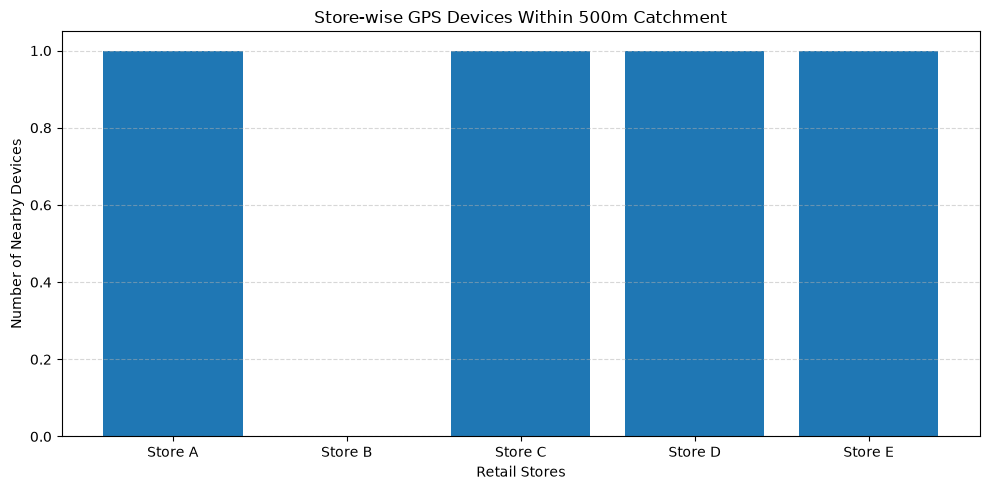

In [8]:
plt.figure(figsize=(10, 5))

plt.bar(
    catchment_summary["StoreName"],
    catchment_summary["Unique_Devices"]
)

plt.title("Store-wise GPS Devices Within 500m Catchment")
plt.xlabel("Retail Stores")
plt.ylabel("Number of Nearby Devices")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [9]:
# Save detailed spatial analysis
spatial_df.to_csv(
    DATA_DIR / "geopulse_spatial_analysis.csv",
    index=False
)

# Save store-wise catchment summary
catchment_summary.to_csv(
    DATA_DIR / "geopulse_spatial_summary.csv",
    index=False
)

print("Files saved successfully!")

print("\n1. geopulse_spatial_analysis.csv")
print("2. geopulse_spatial_summary.csv")

Files saved successfully!

1. geopulse_spatial_analysis.csv
2. geopulse_spatial_summary.csv


In [10]:
print("Detailed Analysis Shape:", spatial_df.shape)

print("\nCatchment Summary:")
display(catchment_summary)

print("\nValidation Checks:")
print("Total comparisons:", len(spatial_df))
print("500m matches:", spatial_df["Within_500m"].sum())
print("Stores analyzed:", catchment_summary["StoreID"].nunique())
print("Missing values:", spatial_df.isnull().sum().sum())

print("\nAll checks completed!")

Detailed Analysis Shape: (500, 6)

Catchment Summary:


,StoreID,StoreName,Unique_Devices,Total_GPS_Visits
0,S001,Store A,1,1
1,S002,Store B,0,0
2,S003,Store C,1,1
3,S004,Store D,1,1
4,S005,Store E,1,1



Validation Checks:
Total comparisons: 500
500m matches: 4
Stores analyzed: 5
Missing values: 0

All checks completed!
